# Latent Confounding and DoWhy

In a discovery-to-estimation workflow, effect identification depends on the causal assumptions encoded in the learned graph. When that graph is estimated from data, those assumptions include both the returned edges and the conditions under which the discovery procedure is valid.

One important condition is **causal sufficiency**: no unobserved variable is a common cause of multiple observed variables. That condition can be difficult to justify in time-series applications. An unmeasured weather system may affect several river gauges; a macroeconomic shock may move multiple assets; a shared environmental factor may influence several genes.

When such a driver is omitted, its shared influence can be represented as spurious adjacencies or incorrect orientations among the observed series. Passing that graph to DoWhy does not repair the misspecification: identification and estimation proceed under the assumptions represented by the supplied graph.

This notebook follows that failure downstream and then shows two ways to use a corrected graph:

1. **Convenience path:** estimate an effect directly from a `causal-ts` result object.
2. **Artifact path:** export a query-specific graph and lag-aligned frame, then continue with the native DoWhy API.

Section 1 isolates the failure in a three-variable example. Section 2 uses a higher-dimensional system with pervasive latent-factor confounding, applies **LUCID**, and compares the graph before and after correction.

> **Scope.** LUCID is a structural post-processing method with its own regime assumptions. It can improve the observed-variable graph; it does not turn an unobserved confounder into an observed adjustment variable.


In [1]:
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Silence only the optional Jupyter progress-bar warning, and LUCID's notice
# that we are reusing a discovered skeleton -- which is exactly what we intend
# here, so that the routing comparison sees the same graph the table scored.
warnings.filterwarnings("ignore", message="IProgress not found.*")
warnings.filterwarnings("ignore", message="reusing a discovery result.*")
warnings.filterwarnings("ignore", message="The given NumPy array is not writable.*")

from causalts import run_cdnots, run_lucid
from causalts.ci_tests import ParCorrGPU
from causalts.plotting import compare_graphs, plot_graph
from causalts.tigramite_discovery import run_pcmciplus, tigramite_graph_to_binary
from causalts.utils.helpers import evaluate_graph

RNG_SEED = 7
ALPHA = 0.01
CI_DEVICE = "cpu"  # portable across notebook environments

# Graphviz layout shared across comparison panels.
GV = {"args": "-Goverlap=scale -Gsplines=true"}
LAYOUT = "fdp"

np.random.seed(0)

## 1. An Omitted Driver Becomes an Edge

Consider three series:

- `Heat(t)` raises `IceCream(t)` sales.
- `Heat(t-1)` raises shark `Attacks(t)` with a one-step delay.
- `IceCream` has no causal effect on `Attacks`.

The cross-variable structure is therefore:

> `Heat(t) -> IceCream(t)` and `Heat(t-1) -> Attacks(t)`

`IceCream` and `Attacks` also have autoregressive self-effects. The target effect, from `IceCream(t-1)` to `Attacks(t)`, is exactly **zero**. We generate one dataset and analyze it twice: first with `Heat` recorded, then with `Heat` omitted. [`latent_confounder_detection.ipynb`](latent_confounder_detection.ipynb) uses the same story to motivate LUCID; here we follow it into effect estimation.


In [2]:
rng = np.random.default_rng(RNG_SEED)
T = 1500

heat = rng.standard_normal(T) + 1.5 * np.sin(np.arange(T) * 2 * np.pi / 365)
ice = np.zeros(T)
att = np.zeros(T)

for t in range(1, T):
    ice[t] = 0.3 * ice[t - 1] + 0.9 * heat[t] + 0.3 * rng.standard_normal()
    att[t] = 0.3 * att[t - 1] + 0.8 * heat[t - 1] + 0.3 * rng.standard_normal()

full = pd.DataFrame({"Heat": heat, "IceCream": ice, "Attacks": att})
observed = full[["IceCream", "Attacks"]].copy()

print(f"T = {T}")
print("true cross-variable edges: Heat(t) -> IceCream(t), Heat(t-1) -> Attacks(t)")
print("true effect of IceCream(t-1) on Attacks(t): 0.0")


T = 1500
true cross-variable edges: Heat(t) -> IceCream(t), Heat(t-1) -> Attacks(t)
true effect of IceCream(t-1) on Attacks(t): 0.0


### Discovery With and Without Heat

We run **CDNOTS** twice with the same lag limit, conditional-independence test, and significance level. The time-index node is disabled (`include_C=False`) so the only change is whether `Heat` is available to discovery.


In [3]:
def discover(frame):
    ci = ParCorrGPU(frame.values.copy(), device=CI_DEVICE)
    return run_cdnots(
        frame,
        ci,
        num_lags=2,
        include_C=False,
        alpha=ALPHA,
    )


def relation_list(result, frame):
    """Format cross-variable relations, counting a reciprocal lag-0 pair once."""
    graph = np.asarray(result.cg_tig)
    names = list(frame.columns)
    out = []

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            ij, ji = bool(graph[i, j, 0]), bool(graph[j, i, 0])
            if ij and ji:
                out.append(f"{names[i]}(t) — {names[j]}(t) [unoriented]")
            elif ij:
                out.append(f"{names[i]}(t) -> {names[j]}(t)")
            elif ji:
                out.append(f"{names[j]}(t) -> {names[i]}(t)")

    for lag in range(1, graph.shape[2]):
        for i in range(len(names)):
            for j in range(len(names)):
                if i != j and graph[i, j, lag]:
                    out.append(f"{names[i]}(t-{lag}) -> {names[j]}(t)")
    return out


res_full = discover(full)
res_obs = discover(observed)

for label, result, frame in [
    ("Heat RECORDED", res_full, full),
    ("Heat MISSING", res_obs, observed),
]:
    print(f"{label}:")
    for relation in relation_list(result, frame):
        print("   ", relation)
    print()


Heat RECORDED:
    Heat(t) -> IceCream(t)
    Heat(t-1) -> Attacks(t)

Heat MISSING:
    IceCream(t-1) -> Attacks(t)
    Attacks(t-2) -> IceCream(t)



With `Heat` observed, discovery recovers both true relations, including the contemporaneous `Heat(t) -> IceCream(t)`, and finds no `IceCream`–`Attacks` relation.

When `Heat` is omitted, the same procedure adds `IceCream(t-1) -> Attacks(t)` and a reverse lag-2 relation. The precise error pattern is specific to this simulation; the general failure is that a missing fork is represented by spurious relations among the observed variables.

### Effect Estimate with DoWhy

The result object can be sent directly to DoWhy through `estimate_effect()`. The bridge constructs the lag embedding, exports the graph, identifies an estimand, and estimates it. We print the adjustment set because it makes the identifying claim explicit.

Both graphs here are fully oriented, so `cycle_resolution="drop"` changes nothing in this part; the same call is reused later on graphs where it does matter. Ambiguous contemporaneous relations require substantive judgment; dropping one direction is not a generally safe default.


In [4]:
for label, result in [("Heat recorded", res_full), ("Heat missing", res_obs)]:
    estimate = result.estimate_effect(
        "IceCream",
        "Attacks",
        treatment_lag=1,
        cycle_resolution="drop",
        confidence_intervals=False,
    )
    adjustment = sorted(estimate.target_estimand.get_adjustment_set())
    structural = estimate.target_estimand.no_directed_path
    kind = "no directed path" if structural else "fitted regression"

    print(
        f"{label:13s} ATE = {float(estimate.value):+.4f} "
        f"[{kind}]"
    )
    print(f"{'':13s} adjustment set = {adjustment}")

print("\nground truth  ATE = +0.0000")


Heat recorded ATE = +0.0000 [no directed path]
              adjustment set = ['Heat_lag1', 'IceCream_lag2']
Heat missing  ATE = +0.8353 [fitted regression]
              adjustment set = ['Attacks_lag3', 'IceCream_lag2']

ground truth  ATE = +0.0000


The exact zero in the first row is **structural**: the supplied graph contains no directed path from treatment to outcome, so no coefficient is fitted. Once `Heat` is omitted, the spurious path makes the effect estimable under the learned graph and the fitted answer is `+0.8353`.

DoWhy estimates under the graph it is given, so the error comes from discovery, not from the estimation step.

### Checking the Graph Against the Data

`validate_transition_graph()` tests the local Markov condition at each current-time node. It can reveal incompatibility between a transition graph and the data without requiring ground truth.


In [5]:
report = res_obs.validate_transition_graph()
print(report.to_frame().to_string(index=False))
print("\nrejected nodes:", ", ".join(report.rejected_nodes))


    node      p_value  adjusted_p_value  rejected
 Attacks 2.540724e-24      5.081448e-24      True
IceCream 2.270350e-05      2.270350e-05      True

rejected nodes: IceCream, Attacks


Both node-wise tests reject after Holm adjustment. This flags the graph as inconsistent with the data, but it does not identify the cause: a hidden common cause, missing edge, reversed edge, or misspecified functional form can all trigger rejection. Conversely, failure to reject would not establish that the graph is correct.


## 2. Pervasive Latent-Factor Confounding

We now simulate 15 observed series driven by three unobserved persistent factors, each an AR(1) process. Each factor loads on a group of five variables. Within each group, two genuine lag-1 cross-variable edges are added, for six in total. Groups 1 and 2 additionally carry one genuine **contemporaneous** edge each, at a strong coefficient of `0.8`. Those two edges matter for what follows: they distinguish a correction that removes spurious contemporaneous structure from one that simply deletes all of it.

Synthetic data are useful here because every true and confounded relation is known. The goal is not to benchmark discovery algorithms; it is to expose the graph error and evaluate a post-hoc correction under controlled conditions.


In [6]:
def make_factor_data(
    d=15,
    n_factors=3,
    T=1500,
    seed=44,
    persistence=0.7,
    contemporaneous=0.8,
    loading_scale=1.0,
):
    """Generate observed series with latent factors and sparse lag-1 edges.

    ``persistence`` is the AR(1) coefficient of each latent factor.
    ``contemporaneous`` is the coefficient of the genuine lag-0 edges planted in
    groups 1 and 2; group 0 is left free of them so the effect query in section 3
    and its proxies are unaffected.
    """
    rng_f = np.random.default_rng([seed, 1])
    rng_l = np.random.default_rng([seed, 2])
    rng_e = np.random.default_rng([seed, 3])
    group_size = d // n_factors

    z = rng_f.normal(size=(T, n_factors))
    stationary_var = 0.01 / (1 - 0.1 - 0.85)

    factors = np.zeros((T, n_factors))
    innovation_sd = np.sqrt(stationary_var * (1 - persistence**2))
    for t in range(1, T):
        factors[t] = persistence * factors[t - 1] + innovation_sd * z[t]

    # A[target, source]: AR(1) self-effects plus planted cross-variable edges.
    A = 0.3 * np.eye(d)
    B = np.zeros((d, d))  # B[target, source] at lag 0
    gt = np.zeros((d, d, 2), dtype=int)
    for i in range(d):
        gt[i, i, 1] = 1  # the AR self-loop is a real edge, so it is scored
    true_edges = []
    for group in range(n_factors):
        start = group * group_size
        for offset in range(2):
            source, target = start + offset, start + offset + 1
            if target < min((group + 1) * group_size, d):
                A[target, source] += 0.4
                gt[source, target, 1] = 1
                true_edges.append((source, target, 1))
        if contemporaneous and group > 0:
            source, target = start + 3, start + 4
            B[target, source] = contemporaneous
            gt[source, target, 0] = 1
            true_edges.append((source, target, 0))

    loadings = rng_l.uniform(0.5, 1.5, size=d) * loading_scale
    group_of = np.minimum(np.arange(d) // group_size, n_factors - 1)
    noise = 0.3 * rng_e.normal(size=(T, d))

    # B is strictly lower-triangular, so the lag-0 block stays acyclic and the
    # simultaneous system has the closed-form solution below.
    solve = np.linalg.inv(np.eye(d) - B)
    data = np.zeros((T, d))
    for t in range(1, T):
        data[t] = solve @ (
            loadings * factors[t, group_of] + A @ data[t - 1] + noise[t]
        )

    gt_full = np.zeros((d + n_factors, d + n_factors, 2), dtype=int)
    gt_full[:d, :d, :] = gt
    for group in range(n_factors):
        lo, hi = group * group_size, min((group + 1) * group_size, d)
        gt_full[d + group, lo:hi, 0] = 1

    observed_names = [f"X{i}" for i in range(d)]
    full_names = observed_names + [f"F{g}" for g in range(n_factors)]
    return (pd.DataFrame(data, columns=observed_names), gt, true_edges,
            gt_full, full_names, factors)


df, gt, true_edges, gt_full, names_full, FACTORS = make_factor_data()
d, max_lag = df.shape[1], 1
names = list(df.columns)
group_size = d // 3
GROUPS = {
    group: [f"X{i}" for i in range(group * group_size, (group + 1) * group_size)]
    for group in range(3)
}

print(f"observed: T={len(df)}, d={d}; latent factors: 3")
lagged = [e for e in true_edges if e[2] == 1]
contemp = [e for e in true_edges if e[2] == 0]
print(f"planted lagged cross-variable edges ({len(lagged)}): {lagged}")
print(f"planted CONTEMPORANEOUS edges ({len(contemp)}): {contemp} — coefficient 0.8")
print("AR(1) self-loop coefficient for every observed series: 0.3")
print(f"latent factors are AR(1) with persistence 0.7; "
      f"lag-1 autocorrelation of F0 = "
      f"{np.corrcoef(FACTORS[1:, 0], FACTORS[:-1, 0])[0, 1]:+.3f}")
for group, members in GROUPS.items():
    print(f"  F{group} drives {members}")

observed: T=1500, d=15; latent factors: 3
planted lagged cross-variable edges (6): [(0, 1, 1), (1, 2, 1), (5, 6, 1), (6, 7, 1), (10, 11, 1), (11, 12, 1)]
planted CONTEMPORANEOUS edges (2): [(8, 9, 0), (13, 14, 0)] — coefficient 0.8
AR(1) self-loop coefficient for every observed series: 0.3
latent factors are AR(1) with persistence 0.7; lag-1 autocorrelation of F0 = +0.717
  F0 drives ['X0', 'X1', 'X2', 'X3', 'X4']
  F1 drives ['X5', 'X6', 'X7', 'X8', 'X9']
  F2 drives ['X10', 'X11', 'X12', 'X13', 'X14']


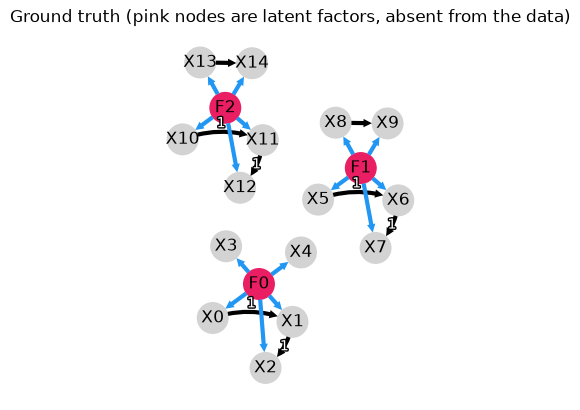

In [7]:
n_factors = len(names_full) - d
plot_graph(
    gt_full,
    val_matrix=None,
    var_names=names_full,
    target_node=[f"F{g}" for g in range(n_factors)],
    target_node_color="#E91E63",
    target_out_color="#E91E63",
    title="Ground truth (pink nodes are latent factors, absent from the data)",
    node_layout=LAYOUT,
    node_layout_kwargs=GV,
)
plt.show()


The figure shows the **cross-variable** ground truth and the latent-factor arrows. The AR(1) self-loops are omitted from the figure to keep it readable, but they are part of the ground-truth graph and are scored.

### CDNOTS and PCMCI+ on the Factor Data

We compare [**CDNOTS**](https://arxiv.org/abs/2312.17375) and [**PCMCI+**](https://arxiv.org/abs/2003.03685) with the same linear CI test, lag limit, and significance level. PCMCI+ is developed for the causally sufficient setting. CDNOTS assumes *pseudo causal sufficiency*: potential confounders handled through its time-index node must be expressible as smooth functions of time. The stochastic AR(1) factors here are not deterministic smooth functions of the observed time index; we also set `include_C=False` so both engines receive only the observed series.

Both engines leave some contemporaneous edges unoriented. We ran the pipeline across five independent seeds as an illustrative stability check rather than a formal benchmark, and the figures shown here use the first seed.

In [8]:
def score_row(seed, method, graph, truth):
    """Score lag-0 edges as adjacencies and lagged edges (AR self-loops included)
    as directed, then pool the counts, so an unoriented lag-0 pair is never given
    a direction."""
    m = evaluate_graph(graph, truth, exclude_self_loops=False)
    tp = m["TP_lag0_adj"] + m["TP_lagpos"]
    fp = m["FP_lag0_adj"] + m["FP_lagpos"]
    fn = m["FN_lag0_adj"] + m["FN_lagpos"]
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "seed": seed,
        "method": method,
        "F1": f1,
        "precision": precision,
        "recall": recall,
        "SHD": m["SHD_lag0_adj"] + m["SHD_lagpos"],
        "FP_lag0": m["FP_lag0_adj"],
        "self_loops_missed": sum(
            1 for i in range(d) if truth[i, i, 1] and not graph[i, i, 1]
        ),
        "true_lag0_kept": m["TP_lag0_adj"],
    }


SCORING_NOTE = (
    "F1, precision, recall and SHD: mean ± sd; other columns: means.\n"
    "Lag-0 edges are scored as adjacencies, lagged edges and AR self-loops as "
    "directed.\n"
    f"missed AR: true self-loops missed (of {d}); true lag0 kept: planted lag-0 "
    "adjacencies found (of 2).\n"
)


def print_summary(stats, methods):
    print(
        f"{'':15s} {'F1':>14s} {'precision':>14s} {'recall':>14s} "
        f"{'SHD':>12s} {'FP lag0':>8s} {'missed AR':>10s} "
        f"{'true lag0 kept':>15s}"
    )
    for method in methods:
        subset = stats[stats.method == method]
        print(
            f"{method:18s} "
            f"{subset['F1'].mean():6.3f}±{subset['F1'].std():<7.3f} "
            f"{subset['precision'].mean():6.3f}±{subset['precision'].std():<7.3f} "
            f"{subset['recall'].mean():6.3f}±{subset['recall'].std():<7.3f} "
            f"{subset['SHD'].mean():5.1f}±{subset['SHD'].std():<6.1f}"
            f"{subset['FP_lag0'].mean():8.1f} "
            f"{subset['self_loops_missed'].mean():10.1f} "
            f"{subset['true_lag0_kept'].mean():13.1f}/2"
        )


SEEDS = [44, 45, 46, 47, 48]
raw_rows = []
runs = {}

for seed in SEEDS:
    df_s, gt_s, *_ = make_factor_data(seed=seed)

    cdnots_result = run_cdnots(
        df_s,
        ParCorrGPU(df_s.values.copy(), device=CI_DEVICE),
        num_lags=max_lag,
        include_C=False,
        alpha=ALPHA,
    )
    cdnots_graph = np.asarray(cdnots_result.cg_tig)[:d, :d, :2]

    _, pcmci_info = run_pcmciplus(
        df_s,
        tau_max=max_lag,
        ci_test=ParCorrGPU(df_s.values.copy(), device=CI_DEVICE),
        pc_alpha=ALPHA,
    )
    # Keep PCMCI+'s unoriented ("o-o") and conflicting ("x-x") contemporaneous
    # edges instead of discarding them, so both engines are scored on the same
    # basis -- run_cdnots keeps its unoriented edges too.
    pcmci_graph_raw = np.asarray(
        tigramite_graph_to_binary(
            pcmci_info["graph_raw"], undirected="bidirected", conflict="bidirected"
        )
    )[:d, :d, :2]
    pcmci_graph = pcmci_graph_raw

    raw_rows.extend(
        [
            score_row(seed, "CDNOTS", cdnots_graph, gt_s),
            score_row(seed, "PCMCI+", pcmci_graph, gt_s),
        ]
    )
    runs[seed] = {
        "df": df_s,
        "gt": gt_s,
        "cdnots_result": cdnots_result,
        "CDNOTS": cdnots_graph,
        "PCMCI+": pcmci_graph,
        "pcmci_raw": pcmci_graph_raw,
        "pcmci_marks": np.asarray(pcmci_info["graph_raw"])[:d, :d, :2],
    }

raw_stats = pd.DataFrame(raw_rows)
print(f"discovery alone, {len(SEEDS)} seeds")
print(SCORING_NOTE)
print_summary(raw_stats, ["CDNOTS", "PCMCI+"])

discovery alone, 5 seeds
F1, precision, recall and SHD: mean ± sd; other columns: means.
Lag-0 edges are scored as adjacencies, lagged edges and AR self-loops as directed.
missed AR: true self-loops missed (of 15); true lag0 kept: planted lag-0 adjacencies found (of 2).

                            F1      precision         recall          SHD  FP lag0  missed AR  true lag0 kept
CDNOTS              0.579±0.041    0.466±0.035    0.765±0.050    25.6±2.7       19.4        5.4           2.0/2
PCMCI+              0.617±0.033    0.462±0.029    0.930±0.039    26.6±2.9       24.0        1.6           2.0/2


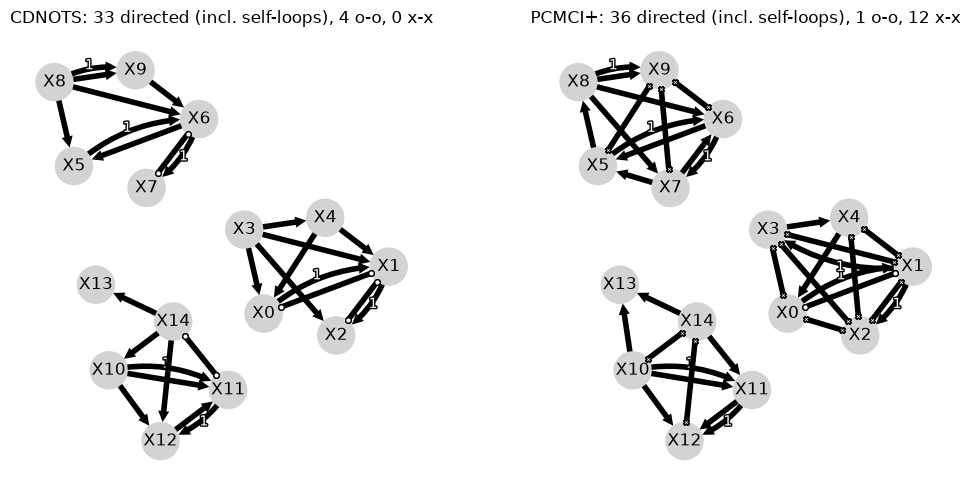

In [9]:
first_run = runs[SEEDS[0]]
gt_d = first_run["gt"]


def mark_counts(marks):
    """o-o and x-x are written on both sides of a pair; count each pair once."""
    counts = Counter(marks.ravel())
    counts.pop("", None)
    return {k: (v // 2 if k in ("o-o", "x-x") else v) for k, v in counts.items()}


def draw_marks(ax, label, marks, node_pos=None):
    counts = mark_counts(marks)
    result = plot_graph(
        marks,
        var_names=names,
        fig_ax=(fig, ax),
        show_colorbar=False,
        arrow_linewidth=4.0,
        node_layout=LAYOUT,
        node_layout_kwargs=GV,
        node_pos=node_pos,
        return_pos=node_pos is None,
    )
    # a directed lag-0 edge is stored as "-->" one way and "<--" the other
    ax.set_title(
        f"{label}: {counts.get('-->', 0)} directed (incl. self-loops), "
        f"{counts.get('o-o', 0)} o-o, {counts.get('x-x', 0)} x-x",
        fontsize=12,
    )
    # plot_graph returns (fig, ax) or (fig, ax, node_pos)
    return result[2] if node_pos is None else None


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
# Lay the nodes out from the denser graph, then reuse those coordinates, so the
# two panels are read as the same 15 variables rather than two unrelated maps.
pos = draw_marks(axes[1], "PCMCI+", first_run["pcmci_marks"])
draw_marks(
    axes[0],
    "CDNOTS",
    np.asarray(first_run["cdnots_result"].to_marks())[:d, :d, :2],
    node_pos=pos,
)
plt.tight_layout()
plt.show()

These are the graphs the engines actually return, with their endpoint marks: an arrowhead is an oriented edge, an open circle (`o-o`) an adjacency the engine could not orient, and a cross (`x-x`) a contradiction between orientation rules. False positives are dominated by contemporaneous relations here — `FP lag0` (false lag-0 adjacencies) averages 19.4 for CDNOTS and 24.0 for PCMCI+ — while the planted cross-variable effects are lagged. The two engines also carry their ambiguity differently: on this draw CDNOTS leaves 4 `o-o` adjacencies and no conflicts, PCMCI+ leaves 1 `o-o` and 12 `x-x`. Both methods therefore retain useful signal but return graphs with low precision under the violated sufficiency assumption.

That lag-0 pattern is a property of this simulation, not a universal diagnostic for latent confounding.

### Correcting the Graph with LUCID

LUCID estimates the confounding regime from residual spectral structure and applies the matching correction. Calling `.deconfound()` on a `causal-ts` result reuses its discovered graph. A graph from another engine can be supplied through `run_lucid(..., discovery=graph)`. How LUCID diagnoses the regime is covered in [`latent_confounder_detection.ipynb`](latent_confounder_detection.ipynb).

In [10]:
corrected_rows = []

for seed, run in runs.items():
    cdnots_lucid = run["cdnots_result"].deconfound()
    cdnots_lucid_graph = np.asarray(cdnots_lucid.cg_tig)[:d, :d, :2]

    pcmci_lucid = run_lucid(run["df"], max_lag, discovery=run["pcmci_raw"])
    pcmci_lucid_graph = np.asarray(pcmci_lucid.cg_tig)[:d, :d, :2]

    # The comparator any practitioner would reach for first: delete every
    # contemporaneous edge. It also yields an acyclic graph -- the question is
    # what it destroys on the way.
    drop_lag0 = run["CDNOTS"].copy()
    drop_lag0[:, :, 0] = 0

    corrected_rows.extend(
        [
            score_row(seed, "CDNOTS + LUCID", cdnots_lucid_graph, run["gt"]),
            score_row(seed, "drop all lag-0", drop_lag0, run["gt"]),
            score_row(seed, "PCMCI+ + LUCID", pcmci_lucid_graph, run["gt"]),
        ]
    )
    run["CDNOTS + LUCID"] = cdnots_lucid_graph
    run["PCMCI+ + LUCID"] = pcmci_lucid_graph
    run["cdnots_lucid_result"] = cdnots_lucid
    run["pcmci_lucid_result"] = pcmci_lucid

stats = pd.concat([raw_stats, pd.DataFrame(corrected_rows)], ignore_index=True)
print(f"discovery + correction, {len(SEEDS)} seeds")
print(SCORING_NOTE)
print_summary(
    stats,
    ["CDNOTS", "CDNOTS + LUCID", "drop all lag-0", "PCMCI+", "PCMCI+ + LUCID"],
)

first = first_run["cdnots_lucid_result"]
print(
    f"\nfirst-draw route: regime={first.regime!r}, router={first.router!r}, "
    f"R={first.spectral_ratio:.3f}, tau={first.tau:.3f}, "
    f"n_factors={first.n_factors}"
)

print("\nfirst-draw factor footprints (largest |loadings|):")
for factor in range(first.n_factors):
    top = first.top_factor_variables(factor, n=5)
    recovered = {name for name, _ in top}
    match = next(
        (group for group, members in GROUPS.items() if recovered == set(members)),
        None,
    )
    variables = ", ".join(f"{name}({value:+.2f})" for name, value in top)
    verdict = (
        f"matches planted group F{match}" if match is not None
        else "mixes planted groups"
    )
    print(f"  factor {factor}: {variables}  [{verdict}]")


def relations(graph):
    return [
        (names[i], names[j], lag)
        for i in range(d)
        for j in range(d)
        for lag in range(graph.shape[2])
        if i != j and graph[i, j, lag]
        # an unoriented lag-0 pair is one relation, not two
        and not (lag == 0 and j < i and graph[j, i, 0])
    ]


raw_relations = relations(first_run["CDNOTS"])
corrected_relations = relations(first_run["CDNOTS + LUCID"])
truth_relations = relations(gt_d)

print(
    "\nfirst-draw cross-variable relations: "
    f"raw={len(raw_relations)}, corrected={len(corrected_relations)}, "
    f"truth={len(truth_relations)}"
)
print("kept after correction:", corrected_relations)

discovery + correction, 5 seeds
F1, precision, recall and SHD: mean ± sd; other columns: means.
Lag-0 edges are scored as adjacencies, lagged edges and AR self-loops as directed.
missed AR: true self-loops missed (of 15); true lag0 kept: planted lag-0 adjacencies found (of 2).

                            F1      precision         recall          SHD  FP lag0  missed AR  true lag0 kept
CDNOTS              0.579±0.041    0.466±0.035    0.765±0.050    25.6±2.7       19.4        5.4           2.0/2
CDNOTS + LUCID      0.850±0.048    0.956±0.046    0.765±0.050     6.2±1.9        0.0        5.4           2.0/2
drop all lag-0      0.792±0.051    0.951±0.052    0.678±0.050     8.2±1.9        0.0        5.4           0.0/2
PCMCI+              0.617±0.033    0.462±0.029    0.930±0.039    26.6±2.9       24.0        1.6           2.0/2
PCMCI+ + LUCID      0.943±0.036    0.956±0.043    0.930±0.039     2.6±1.7        0.0        1.6           2.0/2

first-draw route: regime='pervasive', router='auto

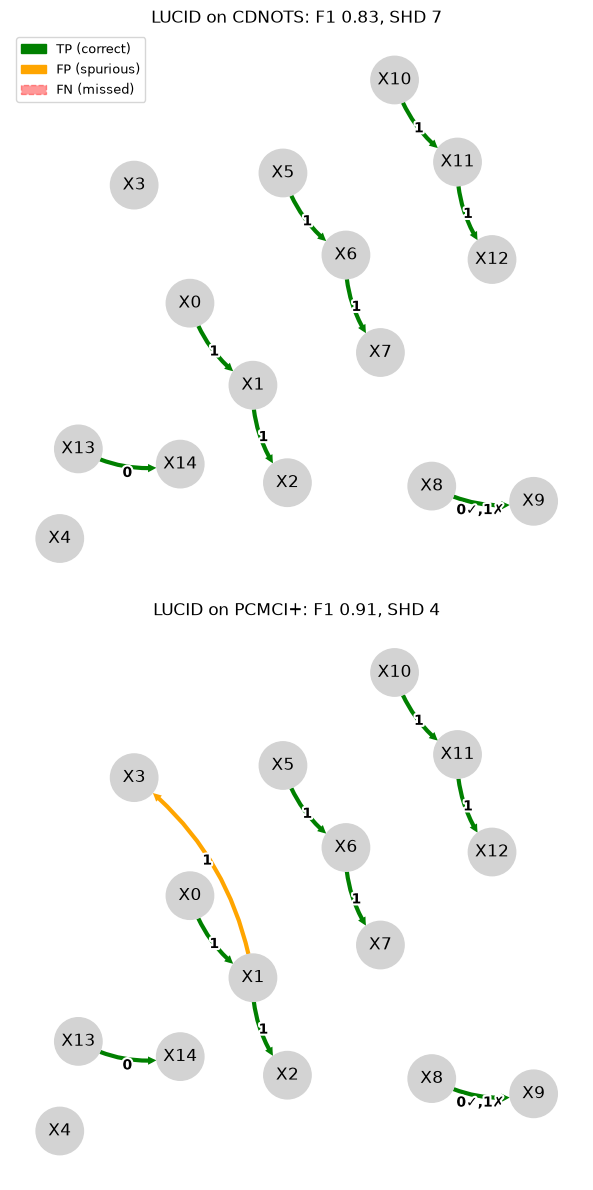

In [11]:
s_cl = score_row(SEEDS[0], "", first_run["CDNOTS + LUCID"], gt_d)
s_pl = score_row(SEEDS[0], "", first_run["PCMCI+ + LUCID"], gt_d)

fig, axes = plt.subplots(2, 1, figsize=(9, 12))
_, _, pos = compare_graphs(
    gt_d,
    first_run["CDNOTS + LUCID"],
    var_names=names,
    fig_ax=(fig, axes[0]),
    show_legend=True,
    return_pos=True,
    legend_loc="upper left",
    title=f"LUCID on CDNOTS: F1 {s_cl['F1']:.2f}, SHD {s_cl['SHD']}",
)
compare_graphs(
    gt_d,
    first_run["PCMCI+ + LUCID"],
    var_names=names,
    fig_ax=(fig, axes[1]),
    node_pos=pos,
    show_legend=False,
    title=f"LUCID on PCMCI+: F1 {s_pl['F1']:.2f}, SHD {s_pl['SHD']}",
)
plt.tight_layout()
plt.show()


In the figure above, green edges are recovered and orange edges are false positives. Self-loops are not drawn, and they account for most of the missed edges and the lower recall. `X8 -> X9` carries two labels: the lag-0 edge is correct (✓) and an extra lag-1 relation is a false positive (✗).

Across these five draws LUCID removes every false contemporaneous relation from both input graphs (`FP lag0` goes to `0.0`, precision rises to `0.96`) **while keeping both genuine contemporaneous edges**. Deleting all lag-0 edges — the obvious first thing to try, and enough on its own to make the graph acyclic — reaches almost the same precision but destroys both real edges, costing `0.09` of recall and `0.06` of F1. LUCID decides which contemporaneous edges are artifacts; deleting all lag-0 edges assumes they all are. This is a result for this controlled system and configuration, not a general recovery guarantee.

The `missed AR` column matters for section 3: correction leaves it untouched at 5.4 missed for CDNOTS and 1.6 for PCMCI+, and the treatment's own lag is among them.

The router selects the pervasive branch and detects three factors, matching the planted count. The top-loading variable sets recover two planted groups cleanly and mix the third. These loadings are **descriptive, not identified**: factor signs, ordering, and basis are non-unique, and LUCID does not recover the latent variables themselves.

## 3. Effect Estimation on the Corrected Graph

A corrected graph should remain usable outside the library that produced it. `causal-ts` exposes both levels of integration:

| Route | Use it when | What `causal-ts` supplies |
|---|---|---|
| `result.estimate_effect(...)` | You want the standard bridge with minimal setup | Lag embedding, graph conversion, identification contract, and DoWhy estimation |
| `result.to_dowhy_identification(...)` | You want to choose and operate DoWhy components yourself | A query-specific unrolled NetworkX DAG and the exactly aligned lagged frame |

For a raw 3D graph from another engine, `wrap_graph(graph, df)` attaches the same bridge methods.

We query a genuine planted edge, `X1(t-1) -> X2(t)`, whose structural coefficient is `0.4`. There is no other directed path between these nodes at this horizon, so the true one-step total effect is also `0.4`.


In [12]:
lucid_result = first_run["cdnots_lucid_result"]
TREAT, TARGET = "X1", "X2"

estimate = lucid_result.estimate_effect(
    TREAT,
    TARGET,
    treatment_lag=1,
    cycle_resolution="drop",
    confidence_intervals=False,
)

print(
    f"causal-ts wrapper ATE: {float(estimate.value):+.4f}   "
    f"adjustment set = {sorted(estimate.target_estimand.get_adjustment_set())}"
)
print("generating direct coefficient: +0.4000")


causal-ts wrapper ATE: +1.1096   adjustment set = ['X0_lag2']
generating direct coefficient: +0.4000


The estimate is far from the true one-step effect `0.4`, and correcting the graph does not fix it. Two things are wrong at once. The graph is missing `X1`'s own AR self-loop, so the treatment-parent adjustment set is built from an incomplete parent list. And adjusting for the treatment's parents is a valid backdoor set only under causal sufficiency, which is violated here, so the path through the latent factor stays open either way.

### Why the Estimate Stays Biased

The next cell separates graph quality from the missing confounder. It runs the same four regressions on three observed-variable graphs: corrected CDNOTS, corrected PCMCI+ (which recovers more self-loops) and the observed-variable ground truth. The latent factor is absent from all three.

The four routes are: no adjustment; adjustment for the treatment's parents in that graph; the same plus a two-stage regression on two proxies of the factor; and the same plus the simulated factor itself. `X3` and `X4` load on the same factor as `X1` and `X2` but have no planted edge to them, which makes them proxies for it. Formal proximal identification needs more (two proxies of specific types plus completeness conditions), so read that route as an illustration rather than a recipe. The factor itself is never available in real data; it shows how much bias is left once the confounder is accounted for.


In [13]:
from collections import Counter

from causalts.effects.wrap import wrap_graph

TRUTH = 0.4
PROXY_W, PROXY_Z = "X3", "X4"  # load on F0; no planted edge to X1 or X2
ROUTES = ["no adjustment", "parent adjustment",
          "  + proxies (two-stage)", "  + simulated factor"]
GRAPHS = ("CDNOTS+LUCID", "PCMCI++LUCID", "ground truth")
results = {(g, r): [] for g in GRAPHS for r in ROUTES}
observed = {g: [] for g in GRAPHS}

for seed in SEEDS:
    frame, gt_s, _, _, _, factors_s = make_factor_data(seed=seed)
    values = frame.values
    y = values[3:, names.index(TARGET)]
    treat = values[2:-1, names.index(TREAT)]
    proxy_w = values[2:-1, names.index(PROXY_W)]
    proxy_z = values[2:-1, names.index(PROXY_Z)]
    oracle = factors_s[2:-1, :1]

    def column(node):
        base, lag = node.rsplit("_lag", 1)
        lag = int(lag)
        return values[3 - lag : len(values) - lag, names.index(base)]

    def coefficient(controls, extra=()):
        design = np.column_stack([np.ones(len(y)), treat, *controls, *extra])
        return np.linalg.lstsq(design, y, rcond=None)[0][1]

    def proximal(controls):
        base = np.column_stack([np.ones(len(y)), treat, *controls])
        stage1 = np.column_stack([base, proxy_z])
        fitted = stage1 @ np.linalg.lstsq(stage1, proxy_w, rcond=None)[0]
        return np.linalg.lstsq(np.column_stack([base, fitted]), y, rcond=None)[0][1]

    for label, bridge in [
        ("CDNOTS+LUCID", runs[seed]["cdnots_lucid_result"]),
        ("PCMCI++LUCID", runs[seed]["pcmci_lucid_result"]),
        ("ground truth", wrap_graph(gt_s, frame)),
    ]:
        adjustment = sorted(
            bridge.estimate_effect(
                TREAT, TARGET, treatment_lag=1, cycle_resolution="drop",
                confidence_intervals=False,
            ).target_estimand.get_adjustment_set()
        )
        observed[label].append(tuple(adjustment))
        controls = [column(node) for node in adjustment]
        results[(label, "no adjustment")].append(coefficient([]))
        results[(label, "parent adjustment")].append(coefficient(controls))
        results[(label, "  + proxies (two-stage)")].append(proximal(controls))
        results[(label, "  + simulated factor")].append(coefficient(controls, [oracle]))

print(f"effect of {TREAT}(t-1) on {TARGET}(t); truth = {TRUTH:+.4f}; "
      f"{len(SEEDS)} seeds\n")
for label in GRAPHS:
    shown = "; ".join("{" + ", ".join(s) + "}" + f" [{n}/{len(SEEDS)}]"
                      for s, n in Counter(observed[label]).most_common())
    print(f"  {label:13s} -> adjustment set: {shown}")

for label in GRAPHS:
    print(f"\n{label}")
    print(f"  {'route':26s} {'mean':>8s} {'sd':>7s} {'mean |error|':>13s}")
    for route in ROUTES:
        v = np.array(results[(label, route)])
        print(f"  {route:26s} {v.mean():+8.3f} {v.std(ddof=1):7.3f} "
              f"{np.mean(np.abs(v - TRUTH)):13.3f}")


effect of X1(t-1) on X2(t); truth = +0.4000; 5 seeds

  CDNOTS+LUCID  -> adjustment set: {X0_lag2} [4/5]; {X0_lag2, X1_lag2} [1/5]
  PCMCI++LUCID  -> adjustment set: {X0_lag2} [3/5]; {X0_lag2, X1_lag2} [2/5]
  ground truth  -> adjustment set: {X0_lag2, X1_lag2} [5/5]

CDNOTS+LUCID
  route                          mean      sd  mean |error|
  no adjustment                +0.997   0.161         0.597
  parent adjustment            +1.025   0.211         0.625
    + proxies (two-stage)      +0.438   0.090         0.058
    + simulated factor         +0.521   0.097         0.138

PCMCI++LUCID
  route                          mean      sd  mean |error|
  no adjustment                +0.997   0.161         0.597
  parent adjustment            +1.015   0.215         0.615
    + proxies (two-stage)      +0.433   0.095         0.063
    + simulated factor         +0.495   0.117         0.120

ground truth
  route                          mean      sd  mean |error|
  no adjustment               

`X1` and `X2` load on the same factor, so a factor shock moves both and inflates the estimate: without adjustment it is `+0.997` against `0.4`. Parent adjustment does not help on any of the three graphs (mean |error| 0.597–0.625). The two-stage proxy regression brings the mean |error| down to 0.058–0.068 on all three. Adding the simulated factor gives `+0.387` (mean |error| 0.021) with the observed-variable ground truth, but leaves 0.120–0.138 with either discovered graph; once the confounder is handled, what remains is their graph error.

PCMCI+ recovers a clearly better graph than CDNOTS and finds the treatment's own lag on one more seed, yet parent adjustment moves only from a mean |error| of 0.625 to 0.615, and the observed-variable ground truth still sits at 0.597. Better edge recovery alone does not fix a causally insufficient query.

### Native DoWhy: Arrow Strength from an Exported Graph

`to_dowhy_identification()` returns the query-specific unrolled graph (a `networkx.DiGraph`) together with the lag-aligned frame whose columns match its nodes, so the artifacts work directly in native DoWhy: estimators, refuters, d-separation, or a `gcm` model. The separate `to_dowhy_transition()` export is for fitting current-time mechanisms given observed history; the two are not interchangeable.

The next cells export the query graph, count its backdoor paths, then fit a DoWhy SCM and rank the direct contributions to `X2`. Arrow strength measures how much of `X2`'s variance each incoming edge removes; it is a different quantity from the effect estimate above.


In [14]:
import networkx as nx

from causalts.effects.wrap import wrap_graph

artifacts = lucid_result.to_dowhy_identification(
    TREAT, TARGET, treatment_lag=1, cycle_resolution="drop"
)
G = artifacts.graph
treatment_node, outcome_node = artifacts.query["treatment"], artifacts.query["outcome"]


def backdoor_paths(graph, treatment, outcome):
    into_treatment = set(graph.predecessors(treatment))
    return [
        path
        for path in nx.all_simple_paths(graph.to_undirected(), treatment, outcome)
        if len(path) > 2 and path[1] in into_treatment
    ]


truth_art = wrap_graph(gt_d, df).to_dowhy_identification(
    TREAT, TARGET, treatment_lag=1, cycle_resolution="drop"
)
print(f"unrolled export: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges, "
      f"horizon {artifacts.horizon}; columns match nodes: "
      f"{set(G.nodes) == set(artifacts.data.columns)}")
print(f"backdoor paths -- corrected graph: "
      f"{len(backdoor_paths(G, treatment_node, outcome_node))}, "
      f"ground truth: "
      f"{len(backdoor_paths(truth_art.graph, treatment_node, outcome_node))} "
      f"{backdoor_paths(truth_art.graph, treatment_node, outcome_node)}")


unrolled export: 6 nodes, 5 edges, horizon 2; columns match nodes: True
backdoor paths -- corrected graph: 0, ground truth: 1 [['X1_lag1', 'X1_lag2', 'X2_lag1', 'X2']]



native gcm on the 6-node export :   6.0s
lucid_result.arrow_strength() over 15 variables :   8.3s


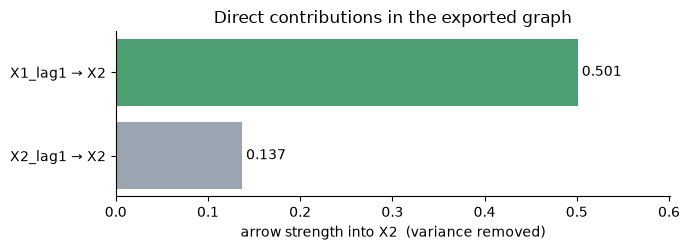

In [15]:
import time

import dowhy.gcm as gcm

gcm.config.disable_progress_bars()

# A structural causal model over the export -- six nodes, so this is fast.
started = time.perf_counter()
scm = gcm.InvertibleStructuralCausalModel(G)
gcm.auto.assign_causal_mechanisms(scm, artifacts.data)
gcm.fit(scm, artifacts.data)
strength = gcm.arrow_strength(scm, target_node=outcome_node)
export_seconds = time.perf_counter() - started

# The same question asked through causal-ts, over all d variables rather than
# the six this query needs.
started = time.perf_counter()
library_ranking = lucid_result.arrow_strength(TARGET)
library_seconds = time.perf_counter() - started

print(f"\nnative gcm on the {G.number_of_nodes()}-node export : "
      f"{export_seconds:5.1f}s")
print(f"lucid_result.arrow_strength() over {d} variables : "
      f"{library_seconds:5.1f}s")

edges = sorted(strength.items(), key=lambda kv: kv[1])
labels = [f"{parent} → {child}" for (parent, child), _ in edges]
values = [v for _, v in edges]

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(labels, values, color=["#4C9F70" if "X1_lag1" in lab else "#9AA5B1"
                               for lab in labels])
for y, v in enumerate(values):
    ax.text(v, y, f" {v:.3f}", va="center", fontsize=10)
ax.set_xlabel("arrow strength into " + outcome_node + "  (variance removed)")
ax.set_title("Direct contributions in the exported graph")
ax.set_xlim(0, max(values) * 1.2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Both routes rank `X1_lag1 -> X2` first and take comparable time; the chart plots the export's values. The library methods (`arrow_strength()`, `parent_relevance()`, `causal_influence()`, `attribute_anomaly()`, `fit_scm()`) cover all 15 variables, while the export is the six-node ancestral subgraph this query needs.

The backdoor counts show what the graph alone cannot settle. The corrected export has **0** backdoor paths, so the empty set already satisfies the backdoor criterion there. The observed-variable ground truth has **1**, `X1_lag1 <- X1_lag2 -> X2_lag1 -> X2`. Neither graph contains the latent factor, which is why a valid identification result is still only as good as its causal-sufficiency assumption.

If you drive estimation natively, `force_parent_adjustment_set()` applies the parent-adjustment convention the wrapper uses, `verify_parent_adjustment_set()` confirms DoWhy kept it, and `effect_modifiers=[]` asks for the same ATE specification.

## Summary

1. An omitted common driver can be converted into observed-variable edges and then into a non-zero downstream effect estimate.
2. In this controlled factor system both discovery engines return many false contemporaneous relations; LUCID removes them while keeping both planted contemporaneous edges, which deleting all lag-0 edges does not.
3. A corrected result can be used through the convenience wrapper or exported as first-class DoWhy artifacts.
4. Structural correction does not guarantee effect identification when the confounder remains unobserved.

Latent-aware discovery methods such as the [FCI family](https://doi.org/10.1016/j.artint.2008.08.001) and [LPCMCI](https://arxiv.org/abs/2007.01884) address a different workflow by returning partially oriented structures that allow hidden common causes. This notebook instead studies sufficiency-based, DAG-like output followed by post-hoc correction before effect analysis.

**Next steps**

- [`latent_confounder_detection.ipynb`](latent_confounder_detection.ipynb) — LUCID in depth: diagnosing sparse vs pervasive confounding
- [`effect_estimation.ipynb`](effect_estimation.ipynb) — the full DoWhy bridge: effects, SCMs, counterfactuals, refutation
- [`tigramite_integration.ipynb`](tigramite_integration.ipynb) — running PCMCI+ and converting its graphs
